# Linear Programming: Graphical, Simplex, Big-M, Two-Phase, and Sensitivity Analysis


This notebook develops linear-programming models and solves them using graphical reasoning, explicit Simplex tableau operations, and numerical optimization. Each numerical problem includes the decision context, data, individual constraints, algorithm calculations, solver checks, and interpretation of the results.

The examples cover paint production, feed blending, machine-capacity allocation, and multi-product manufacturing. The last production-planning dataset is illustrative rather than measured plant data.

**Methods and tools:** NumPy performs matrix and tableau operations; Pandas displays intermediate results; Matplotlib produces graphs; SciPy/HiGHS independently solves the linear programs. The tableau implementation is intended to explain pivot operations, not to replace a maintained industrial solver.

**Units:** In the paint model, the objective $z=5x_1+4x_2$ is measured in *thousands of dollars per day*. An objective value of $21$ corresponds to USD 21,000 per day.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.optimize import linprog
from IPython.display import display
pd.set_option("display.precision", 5)
np.set_printoptions(precision=5, suppress=True)
print("Environment ready: NumPy, Pandas, Matplotlib, SciPy/HiGHS")

Environment ready: NumPy, Pandas, Matplotlib, SciPy/HiGHS


## 1. Graphical LP solution — Reddy Mikks maximization

**Problem description.** A plant produces **exterior paint** ($x_1$, tons/day) and **interior paint** ($x_2$, tons/day). Profit per ton is $5,000$ and $4,000$. Raw-material, market-mix, and interior-demand constraints limit production.


$$
\max z=5x_1+4x_2\quad (\$1{,}000/\text{day})
$$


$$
\begin{aligned}6x_1+4x_2&\le24&&\text{material M1}\\x_1+2x_2&\le6&&\text{material M2}\\-x_1+x_2&\le1&&\text{market balance}\\x_2&\le2&&\text{interior limit}\\x_1,x_2&\ge0.\end{aligned}
$$


**Graphical algorithm:** (1) draw each equality boundary, test which half-plane satisfies each inequality, and intersect them with $x_1,x_2\ge0$; (2) find feasible vertices; (3) move a parallel objective line $5x_1+4x_2=k$ in the increasing-$k$ direction until it last touches the feasible polygon. The optimum is attained at a vertex when a finite optimum exists (possibly among multiple optimal vertices).

### Production data and the meaning of every constraint

**Production setting.** Profit is measured in thousands of dollars per day. Management chooses how many **tons per day** of exterior ($x_1$) and interior ($x_2$) paint to make. Each ton of exterior paint contributes **\$5,000**, and each ton of interior paint contributes **\$4,000**. Two materials have daily availability limits. Marketing additionally requires interior output to exceed exterior output by **no more than one ton**, and interior demand is capped at two tons per day.

| Restriction | Exterior per ton | Interior per ton | Available/limit | Interpretation |
|---|---:|---:|---:|---|
| Raw material M1 | 6 | 4 | 24 | $6x_1+4x_2\le24$ |
| Raw material M2 | 1 | 2 | 6 | $x_1+2x_2\le6$ |
| Market mix | −1 | +1 | +1 | $x_2-x_1\le1$ |
| Interior demand | 0 | 1 | 2 | $x_2\le2$ |

We allow continuous nonnegative production amounts, assuming no fixed setup charges or uncertain processing yields. The question is **which daily production mix gives the greatest contribution margin without violating material or market restrictions?**

**Graph every boundary separately.** For M1 the intercepts are $(0,6)$ and $(4,0)$; for M2 they are $(0,3)$ and $(6,0)$. Market mix has boundary $x_2=x_1+1$ (points $(0,1)$ and $(1,2)$), and the interior limit is the horizontal line $x_2=2$. Test $(0,0)$ for the inequality side: it satisfies each of the four inequalities. The feasible region is their common intersection in the first quadrant.


In [2]:
A_rm = np.array([[6,4],[1,2],[-1,1],[0,1]],dtype=float)
b_rm = np.array([24,6,1,2],dtype=float)
c_rm = np.array([5,4],dtype=float)
labels_rm=["M1","M2","Market","Interior cap"]
def feasible_vertices(A,b,tol=1e-8):
    boundary=np.vstack([A,[-1.,0.],[0.,-1.]])
    rhs=np.r_[b,0.,0.]
    verts=[]
    for ij in combinations(range(len(rhs)),2):
        mat=boundary[list(ij)]
        if abs(np.linalg.det(mat))<tol: continue
        x=np.linalg.solve(mat,rhs[list(ij)])
        if np.all(boundary@x <= rhs+tol) and not any(np.linalg.norm(x-v)<tol for v in verts): verts.append(x)
    return np.array(sorted(verts,key=lambda x:np.arctan2(x[1]-np.mean([v[1] for v in verts]),x[0]-np.mean([v[0] for v in verts]))))
V=feasible_vertices(A_rm,b_rm)
vertices=pd.DataFrame(V,columns=["x1 (ton)","x2 (ton)"])
vertices["z ($1,000/day)"]=V@c_rm
vertices=vertices.sort_values(["x1 (ton)","x2 (ton)"]).reset_index(drop=True)
display(vertices)
best=vertices.loc[vertices["z ($1,000/day)"].idxmax()]
print("Optimal vertex:",best.to_dict())

,x1 (ton),x2 (ton),"z ($1,000/day)"
0,-0.0,-0.0,0.0
1,-0.0,1.0,4.0
2,1.0,2.0,13.0
3,2.0,2.0,18.0
4,3.0,1.5,21.0
5,4.0,-0.0,20.0


Optimal vertex: {'x1 (ton)': 3.0, 'x2 (ton)': 1.4999999999999998, 'z ($1,000/day)': 21.0}


**Read the table:** each row is a feasible corner point found by intersecting pairs of boundary lines and checking **all** inequalities. The largest reported objective is the graphical optimum. The continuum of interior feasible points does not have to be enumerated.

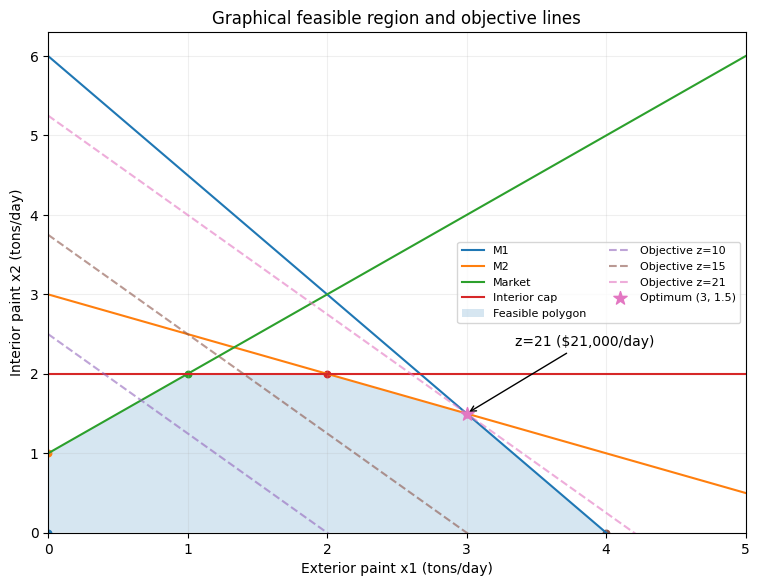

In [3]:
xx=np.linspace(0,5.2,400)
fig,ax=plt.subplots(figsize=(9,6.5))
for row,bi,label in zip(A_rm,b_rm,labels_rm):
    a1,a2=row
    if abs(a2)>1e-10: ax.plot(xx,(bi-a1*xx)/a2,label=label)
    else: ax.axvline(bi/a1,label=label)
from matplotlib.patches import Polygon
ax.add_patch(Polygon(V,closed=True,alpha=.18,label="Feasible polygon"))
for k in (10,15,21):ax.plot(xx,(k-5*xx)/4,'--',alpha=.6,label=f'Objective z={k}')
for _,r in vertices.iterrows():ax.scatter(r.iloc[0],r.iloc[1],s=22)
ax.scatter([3],[1.5],s=100,marker='*',zorder=6,label='Optimum (3, 1.5)')
ax.annotate('z=21 ($21,000/day)',(3,1.5),xytext=(3.35,2.35),arrowprops={'arrowstyle':'->'})
ax.set(xlim=(0,5),ylim=(0,6.3),xlabel='Exterior paint x1 (tons/day)',ylabel='Interior paint x2 (tons/day)',title='Graphical feasible region and objective lines')
ax.grid(alpha=.2);ax.legend(fontsize=8,ncol=2);plt.show()

**Manual intersection at the optimum:** both raw-material constraints bind:


$$
6x_1+4x_2=24,\qquad x_1+2x_2=6.
$$


Subtract twice the second equation from the first: $4x_1=12$, so $x_1=3$; then $3+2x_2=6$ gives $x_2=1.5$.


$$
z=5(3)+4(1.5)=21\ \text{thousand dollars/day}.
$$


At this point, market balance is $-3+1.5=-1.5\le1$ (slack $2.5$), while the interior cap has slack $2-1.5=0.5$. Verify programmatically before interpreting the solution.

The profit comparison must be made across **all feasible corners**, rather than assuming the intersection is optimal. For this model the six corners are $(0,0)$, $(4,0)$, $(3,1.5)$, $(2,2)$, $(1,2)$ and $(0,1)$, with respective objective values $0,20,21,18,13,4$ (thousand dollars/day). The table and feasible-region chart above calculate this rather than relying on a visual guess. Since 21 is the largest, $(3,1.5)$ is the maximizing solution. A feasible corner may tie another corner, in which case the entire connecting optimal edge can also be optimal.


In [4]:
xstar=np.array([3.,1.5]); usage=A_rm@xstar;slack=b_rm-usage
checks=pd.DataFrame({"constraint":labels_rm,"LHS":usage,"RHS":b_rm,"slack":slack,"binding":np.isclose(slack,0)})
display(checks);assert np.all(slack>=-1e-9)
print("Production decision: 3 tons exterior, 1.5 tons interior; profit $21,000/day")

,constraint,LHS,RHS,slack,binding
0,M1,24.0,24.0,0.0,True
1,M2,6.0,6.0,0.0,True
2,Market,-1.5,1.0,2.5,False
3,Interior cap,1.5,2.0,0.5,False


Production decision: 3 tons exterior, 1.5 tons interior; profit $21,000/day


## Graphical minimization — Ozark Farms feed blending

**Problem.** Ozark Farms requires at least **800 lb/day** of feed made from corn and soybean meal. Corn costs **$0.30/lb** and contains 9% protein and 2% fiber. Soybean meal costs **$0.90/lb** and contains 60% protein and 6% fiber. The final feed must be at least **30% protein**, and at most **5% fiber**. Determine the minimum-cost daily mix.

Define $x_1=$ corn (lb/day), $x_2=$ soybean meal (lb/day). The objective is the actual daily expense:


$$
\min z=0.30x_1+0.90x_2\quad (\$/day).
$$


**Constraint derivation, before rearranging:**


$$
\begin{aligned}
 x_1+x_2&\ge800 &&\text{total feed}\quad\text{(D1)}\\
 0.09x_1+0.60x_2&\ge0.30(x_1+x_2) &&\text{protein}\quad\text{(D2)}\\
 0.02x_1+0.06x_2&\le0.05(x_1+x_2) &&\text{fiber}\quad\text{(D3)}\\
 x_1,x_2&\ge0.
\end{aligned}
$$


The fraction-based constraints are linear because the percentages are fixed. Moving terms yields $0.21x_1-0.30x_2\le0$ and $-0.03x_1+0.01x_2\le0$ (the latter expresses $x_2\le3x_1$). Plot the two boundary rays and the minimum-feed boundary. The minimization objective line moves *toward* the origin until it first touches the feasible region. This region is unbounded, but the **minimum cost is finite**.

Unlike a resource-availability constraint, the feed quantity is a lower bound. Setting it to an equality *before* solving can incorrectly exclude feasible solutions if other restrictions make more feed necessary.

Corn = 470.588235 lb/day; soy meal = 329.411765 lb/day; minimum = $437.6471/day
Feed = 800.00 lb; protein proportion = 30.000%; fiber proportion = 3.647%


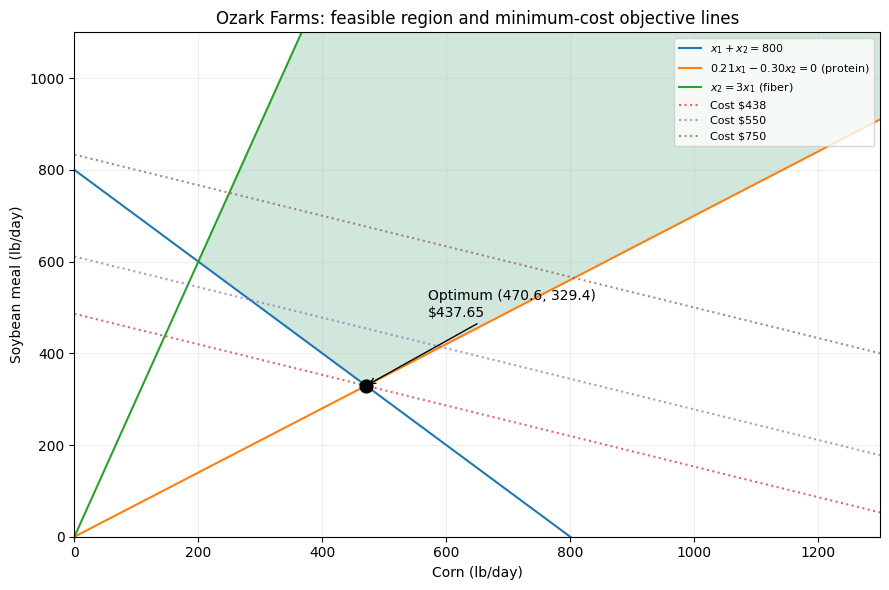

In [5]:
from scipy.optimize import linprog
from matplotlib.patches import Polygon
A_diet=np.array([[-1,-1],[0.21,-0.30],[-0.03,0.01]],float)
b_diet=np.array([-800,0,0],float)
c_diet=np.array([.30,.90],float)
diet=linprog(c_diet,A_ub=A_diet,b_ub=b_diet,bounds=[(0,None)]*2,method='highs-ds')
assert diet.success
x_corn,x_soy=diet.x
print(f'Corn = {x_corn:.6f} lb/day; soy meal = {x_soy:.6f} lb/day; minimum = ${diet.fun:.4f}/day')
print(f'Feed = {x_corn+x_soy:.2f} lb; protein proportion = {(0.09*x_corn+0.60*x_soy)/(x_corn+x_soy):.3%}; fiber proportion = {(0.02*x_corn+0.06*x_soy)/(x_corn+x_soy):.3%}')
fig,ax=plt.subplots(figsize=(9,6))
xx=np.linspace(0,1300,500);yy=np.linspace(0,1300,500)
X,Y=np.meshgrid(xx,yy)
mask=((X+Y>=800)&(0.21*X-0.30*Y<=1e-7)&(-0.03*X+0.01*Y<=1e-7))
ax.contourf(X,Y,mask.astype(float),levels=[.5,1.5],colors=['#b9dbca'],alpha=.65)
ax.plot(xx,800-xx,label=r'$x_1+x_2=800$')
ax.plot(xx,.7*xx,label=r'$0.21x_1-0.30x_2=0$ (protein)')
ax.plot(xx,3*xx,label=r'$x_2=3x_1$ (fiber)')
for v in [diet.fun,550,750]: ax.plot(xx,(v-.3*xx)/.9,':',alpha=.7,label=f'Cost ${v:.0f}')
ax.scatter([x_corn],[x_soy],s=85,color='black',zorder=5)
ax.annotate(f'Optimum ({x_corn:.1f}, {x_soy:.1f})\n${diet.fun:.2f}',(x_corn,x_soy),xytext=(570,480),arrowprops={'arrowstyle':'->'})
ax.set(xlim=(0,1300),ylim=(0,1100),xlabel='Corn (lb/day)',ylabel='Soybean meal (lb/day)',title='Ozark Farms: feasible region and minimum-cost objective lines')
ax.legend(loc='upper right',fontsize=8);ax.grid(alpha=.2);plt.tight_layout();plt.show()


**Manual verification.** Both the total-feed and protein constraints bind at the optimum:


$$
x_1+x_2=800,\qquad 0.21x_1-0.30x_2=0.
$$


Hence $x_2=0.7x_1$ and $1.7x_1=800$, giving $x_1=470.5882$ lb and $x_2=329.4118$ lb. Thus $z=0.3(470.5882)+0.9(329.4118)=\$437.6471$ per day. The resulting fiber share is approximately **3.65%**, below the 5% cap. The plot shows why reducing soybean meal further is infeasible: the mixture would fall short of protein requirements.


## 2. From graphical corners to algebraic basic feasible solutions

Introduce nonnegative slack variables $s_1,\dots,s_4$:


$$
\begin{aligned}6x_1+4x_2+s_1&=24\\x_1+2x_2+s_2&=6\\-x_1+x_2+s_3&=1\\x_2+s_4&=2.\end{aligned}
$$


The augmented matrix is $[A\ I]$. An initial basic feasible solution is $x_1=x_2=0$, with $s=(24,6,1,2)$. A **pivot** exchanges one entering nonbasic variable for one leaving basic variable; this moves between neighboring basic feasible solutions. The ratio test ensures the new basic values remain nonnegative.

With our tableau convention for **maximization**, the objective row is $z-c^Tx=0$ initially, so a **negative** reduced entry can improve profit. Stop when all nonbasic objective-row entries are nonnegative (up to tolerance).

### Algebraic corner points and basic solutions: exact example

For $\max z=2x_1+3x_2$ subject to $2x_1+x_2\le4$, $x_1+2x_2\le5$, $x\ge0$, introduce $s_1,s_2\ge0$:


$$
2x_1+x_2+s_1=4,\qquad x_1+2x_2+s_2=5.
$$


There are two equations and four variables. Choose two basic variables and set the others to zero; a nonnegative result is a **basic feasible solution**. This procedure may also yield infeasible basic solutions (negative components), which must be rejected. The following code enumerates the choices and checks them rather than assuming that every algebraic corner is feasible.

In [6]:
from itertools import combinations
A_basic=np.array([[2,1,1,0],[1,2,0,1]],float)
b_basic=np.array([4,5],float)
rows=[]
for basis in combinations(range(4),2):
    B=A_basic[:,basis]
    if abs(np.linalg.det(B))<1e-10:continue
    xb=np.linalg.solve(B,b_basic)
    xfull=np.zeros(4);xfull[list(basis)]=xb
    rows.append({'basic variables':', '.join(np.array(['x1','x2','s1','s2'])[list(basis)]),
                 'x1':xfull[0],'x2':xfull[1],'s1':xfull[2],'s2':xfull[3],
                 'feasible':bool(np.all(xfull>=-1e-9)),'objective z':2*xfull[0]+3*xfull[1]})
display(pd.DataFrame(rows).round(3))

,basic variables,x1,x2,s1,s2,feasible,objective z
0,"x1, x2",1.0,2.0,0.0,0.0,True,8.0
1,"x1, s1",5.0,0.0,-6.0,0.0,False,10.0
2,"x1, s2",2.0,0.0,0.0,3.0,True,4.0
3,"x2, s1",0.0,2.5,1.5,0.0,True,7.5
4,"x2, s2",0.0,4.0,0.0,-3.0,False,12.0
5,"s1, s2",0.0,0.0,4.0,5.0,True,0.0


## 3. Simplex method — every iteration and row operation

For an all-$\le$ LP with nonnegative RHS, the tableau starts as


$$
T_0=\left[\begin{array}{cc|c}-\boldsymbol{c}^{\mathsf T}&\boldsymbol{0}^{\mathsf T}&0\\A&I&\boldsymbol b\end{array}\right].
$$


(columns: decision variables, slacks, RHS). At each iteration:

1. **Entering column:** most negative objective-row coefficient for maximization.
2. **Leaving row:** smallest $b_i/a_{ij}$ among $a_{ij}>0$. A tie can produce degeneracy.
3. **Pivot:** divide pivot row by its positive pivot element, then eliminate the entering-column coefficient in every other row (including the objective row).
4. **Stop:** no negative eligible objective coefficient; a profitable column with no positive constraint coefficient indicates an unbounded objective.

The next cell prints all tableaux and records ratio tests and the entering/leaving decisions. The arithmetic is performed explicitly with row operations; SciPy is used only afterward for verification.

With the tableau convention used here, an entering column $j$ and leaving row $r$ have pivot $p=T_{rj}$. Every iteration applies


$$
R_r^{\mathrm{new}}=\frac{R_r^{\mathrm{old}}}{p},
$$


$$
R_i^{\mathrm{new}}=R_i^{\mathrm{old}}-T_{ij}^{\mathrm{old}}R_r^{\mathrm{new}},\qquad i\ne r.
$$


The ratio test uses only rows with $T_{ij}>0$. The resulting basic variables appear in the tableau's leftmost column, with values shown in its right-hand side.


### Numerical starting tableau — paint production

The four inequalities become equations by introducing nonnegative slacks $s_1,s_2,s_3,s_4$:


$$
\begin{aligned}
6x_1+4x_2+s_1&=24,\\
x_1+2x_2+s_2&=6,\\
-x_1+x_2+s_3&=1,\\
x_2+s_4&=2.
\end{aligned}
$$


The objective equation is $z-5x_1-4x_2=0$. The initial basic variables are $(s_1,s_2,s_3,s_4)$ and nonbasic variables are $(x_1,x_2)=(0,0)$.


$$
\begin{array}{c|rrrrrr|r}
\text{Basic}&x_1&x_2&s_1&s_2&s_3&s_4&\text{RHS}\\\hline
z&-5&-4&0&0&0&0&0\\
s_1&6&4&1&0&0&0&24\\
s_2&1&2&0&1&0&0&6\\
s_3&-1&1&0&0&1&0&1\\
s_4&0&1&0&0&0&1&2
\end{array}
$$


The $-5$ in the objective row makes $x_1$ the entering variable. The admissible ratio test is $24/6=4$ and $6/1=6$, so $s_1$ leaves. The code generates the complete sequence of subsequent tableaux.


In [7]:
def canonical_tableau(A,b,c,basis):
    """Primal simplex tableau for max c @ x subject to A x=b, x>=0, given feasible basis."""
    A=np.asarray(A,float);b=np.asarray(b,float);c=np.asarray(c,float)
    B=A[:,basis]
    inv=np.linalg.inv(B)
    T=np.zeros((A.shape[0]+1,A.shape[1]+1))
    T[1:,:-1]=inv@A;T[1:,-1]=inv@b
    T[0,:-1]=c[basis]@T[1:,:-1]-c
    T[0,-1]=c[basis]@T[1:,-1]
    return T

def show_tableau(T,basis,names,title):
    df=pd.DataFrame(np.round(T,6),columns=names+["RHS"])
    df.insert(0,"Basic",["z"]+[names[i] for i in basis])
    print(title);display(df)

def simplex_trace(A,b,c,basis,names,max_iter=80,tol=1e-9,verbose=True):
    T=canonical_tableau(A,b,c,basis); basis=list(basis);history=[]
    for it in range(max_iter+1):
        x=np.zeros(len(c));x[basis]=T[1:,-1]
        history.append({"iteration":it,"objective":T[0,-1],"x":x.copy(),"basis":basis.copy()})
        if verbose:show_tableau(T,basis,names,f"Tableau {it}: objective {T[0,-1]:.6g}; basis {[names[j] for j in basis]}")
        eligible=[j for j in range(len(c)) if j not in basis and T[0,j]<-tol]
        if not eligible:return {"status":"optimal","T":T,"basis":basis,"history":history,"x":x}
        entering=min(eligible,key=lambda j:(T[0,j],j))
        ratios=[T[i,-1]/T[i,entering] if T[i,entering]>tol else np.inf for i in range(1,len(T))]
        if verbose:print(" Enter:",names[entering],"; ratios:",[round(r,5) if np.isfinite(r) else 'skip' for r in ratios])
        if not np.isfinite(ratios).any():return {"status":"unbounded","T":T,"basis":basis,"history":history}
        leaving_row=int(np.argmin(ratios))+1;leaving=basis[leaving_row-1]
        pivot=T[leaving_row,entering]
        if verbose:print(" Leave:",names[leaving],"; pivot:",round(pivot,6))
        T[leaving_row,:]=T[leaving_row,:]/pivot
        for r in range(len(T)):
            if r!=leaving_row:T[r,:]-=T[r,entering]*T[leaving_row,:]
        T[np.abs(T)<1e-12]=0
        basis[leaving_row-1]=entering
    return {"status":"iteration_limit","T":T,"basis":basis,"history":history}

A_aug=np.hstack([A_rm,np.eye(4)])
c_aug=np.r_[c_rm,np.zeros(4)]
rm=simplex_trace(A_aug,b_rm,c_aug,[2,3,4,5],["x1","x2","s1","s2","s3","s4"])
assert rm['status']=='optimal' and np.allclose(rm['x'][:2],[3,1.5])
print('Final objective:',rm['T'][0,-1])

Tableau 0: objective 0; basis ['s1', 's2', 's3', 's4']


,Basic,x1,x2,s1,s2,s3,s4,RHS
0,z,-5.0,-4.0,0.0,0.0,0.0,0.0,0.0
1,s1,6.0,4.0,1.0,0.0,0.0,0.0,24.0
2,s2,1.0,2.0,0.0,1.0,0.0,0.0,6.0
3,s3,-1.0,1.0,0.0,0.0,1.0,0.0,1.0
4,s4,0.0,1.0,0.0,0.0,0.0,1.0,2.0


 Enter: x1 ; ratios: [np.float64(4.0), np.float64(6.0), 'skip', 'skip']
 Leave: s1 ; pivot: 6.0
Tableau 1: objective 20; basis ['x1', 's2', 's3', 's4']


,Basic,x1,x2,s1,s2,s3,s4,RHS
0,z,0.0,-0.66667,0.83333,0.0,0.0,0.0,20.0
1,x1,1.0,0.66667,0.16667,0.0,0.0,0.0,4.0
2,s2,0.0,1.33333,-0.16667,1.0,0.0,0.0,2.0
3,s3,0.0,1.66667,0.16667,0.0,1.0,0.0,5.0
4,s4,0.0,1.00000,0.00000,0.0,0.0,1.0,2.0


 Enter: x2 ; ratios: [np.float64(6.0), np.float64(1.5), np.float64(3.0), np.float64(2.0)]
 Leave: s2 ; pivot: 1.333333
Tableau 2: objective 21; basis ['x1', 'x2', 's3', 's4']


,Basic,x1,x2,s1,s2,s3,s4,RHS
0,z,0.0,0.0,0.750,0.50,0.0,0.0,21.0
1,x1,1.0,0.0,0.250,-0.50,0.0,0.0,3.0
2,x2,0.0,1.0,-0.125,0.75,0.0,0.0,1.5
3,s3,0.0,0.0,0.375,-1.25,1.0,0.0,2.5
4,s4,0.0,0.0,0.125,-0.75,0.0,1.0,0.5


Final objective: 21.0


**Interpret the path:** each printed tableau reports the **current** basic solution; the entering/leaving variables explain why and where the next move occurs. In the Reddy Mikks model, the sequence is $(0,0)\to(4,0)\to(3,1.5)$ under the most-negative-row-coefficient rule. The final tableau identifies $x_1=3$, $x_2=1.5$ and $z=21$ (thousand dollars/day).

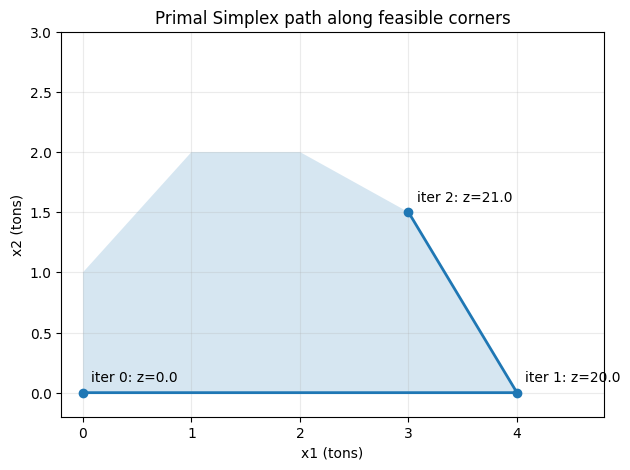

In [8]:
path=np.array([h['x'][:2] for h in rm['history']]);
fig,ax=plt.subplots(figsize=(7,5));ax.add_patch(Polygon(V,closed=True,alpha=.18));ax.plot(path[:,0],path[:,1],'-o',linewidth=2)
for h,pt in zip(rm['history'],path):ax.annotate(f"iter {h['iteration']}: z={h['objective']:.1f}",pt,xytext=(6,8),textcoords='offset points')
ax.set(xlim=(-.2,4.8),ylim=(-.2,3),xlabel='x1 (tons)',ylabel='x2 (tons)',title='Primal Simplex path along feasible corners');ax.grid(alpha=.25);plt.show()

### Individual Simplex pivots: how the numbers change

Use the paint model to show what the tableau operations *mean*. At the origin, $s_1=24$, $s_2=6$, $s_3=1$, $s_4=2$ and $z=0$. The initial objective row is $z-5x_1-4x_2=0$.

**First pivot:** $x_1$ enters because $-5$ is the most negative objective-row coefficient. In the $x_1$ column, the admissible ratios are $24/6=4$ and $6/1=6$; the $-1$ and $0$ column coefficients are excluded. Thus $s_1$ leaves and the pivot is **6**. Normalize $R_{s_1}\leftarrow R_{s_1}/6$, then perform $R_z\leftarrow R_z+5R_{x_1}$, $R_{s_2}\leftarrow R_{s_2}-R_{x_1}$, $R_{s_3}\leftarrow R_{s_3}+R_{x_1}$. This obtains $(x_1,x_2)=(4,0)$ and $z=20$ (in thousands of dollars).

**Second pivot:** the remaining negative objective-row coefficient is $-2/3$ under $x_2$. The positive-column ratios in the current tableau are $4/(2/3)=6$, $2/(4/3)=3/2$, $5/(5/3)=3$, and $2/1=2$. Therefore $s_2$ leaves; the pivot is $4/3$. Normalize $R_{s_2}\leftarrow (3/4)R_{s_2}$, and eliminate $x_2$ from all other rows. The new corner is $(3,1.5)$ and $z=21$. All objective-row reduced-cost signs now satisfy the maximization optimality test.

The printed tableau sequence above is generated by these row operations, so the reader can compare each stated fraction with the corresponding numeric cell. A pivot is a **basis exchange**, not a jump to an arbitrary interior point.

## 4. Artificial starting solutions: Big-M and two-phase methods

An all-slack feasible basis is not immediately available when the constraints include equalities or $\ge$ requirements. A $\ge$ row gets a **surplus variable with coefficient $-1$**, and an equality or such surplus row may need a **temporary artificial variable**.

### Problem description and why artificial variables are required

Management seeks to **minimize a linear operating cost**, $4x_1+x_2$, where $x_1$ and $x_2$ are nonnegative activity levels. The first activity consumes four cost units per unit; the second consumes one. Production must meet an exact blend requirement, a minimum processing requirement, and a maximum-capacity limit:

- **Exact recipe:** $3x_1+x_2=3$. There is no slack to serve as an immediate basic variable.
- **Minimum service:** $4x_1+3x_2\ge6$. Subtracting a surplus variable creates a $-1$ column, not the unit column needed for the initial basis.
- **Maximum available capacity:** $x_1+2x_2\le4$. A nonnegative slack variable supplies an initial basis column.

Here the coefficients are **illustrative model units**, not a documented factory dataset. Artificial variables $r_1$ and $r_2$ are computational devices: they must become zero for a genuinely feasible solution of the original model.


Consider the following two-activity cost-minimization problem:


$$
\begin{aligned}\min z&=4x_1+x_2\\3x_1+x_2&=3\\4x_1+3x_2&\ge6\\x_1+2x_2&\le4\\x_1,x_2&\ge0.\end{aligned}
$$


Equation form (add $r_1,r_2\ge0$ artificial variables):


$$
\begin{aligned}3x_1+x_2+r_1&=3\\4x_1+3x_2-s_2+r_2&=6\\x_1+2x_2+s_3&=4.\end{aligned}
$$


For **Big-M minimization**, $\min z_M=4x_1+x_2+Mr_1+Mr_2$, with $M>0$ sufficiently large. We implement the equivalent **maximization of its negative** so the same tracing code works. Finite $M$ can distort numerical conditioning or even yield a wrong penalty formulation if too small; it is for teaching, not a recommended production approach.

**Big-M algorithm:** (1) convert to equality form; (2) add artificial variables only where needed; (3) penalize each by $+M$ in minimization; (4) construct the consistent canonical objective row by eliminating basic artificial-variable coefficients; (5) pivot by Simplex to optimality; (6) check that all artificial variables vanish. For this example $M=100$ is used solely for a trace; it is not a universal numerical recommendation.


The initial **Big-M** objective is


$$
\min z_M=4x_1+x_2+M(r_1+r_2),\qquad M>0.
$$


With $M=100$, the starting basic solution gives $z_M=100(3+6)=900$; this is the penalty-augmented objective, not the original cost. The temporary variables $r_1,r_2$ must equal zero before the original constraints are satisfied.


In [9]:
A_art=np.array([[3,1,0,0,1,0],[4,3,-1,0,0,1],[1,2,0,1,0,0]],float)
b_art=np.array([3,6,4],float)
vars_art=['x1','x2','surplus','slack','r1','r2']
M=100.0
c_big=-np.array([4,1,0,0,M,M],float)   # maximize negative of penalized min
big=simplex_trace(A_art,b_art,c_big,[4,5,3],vars_art)
assert big['status']=='optimal'
print('Big-M original min objective:',4*big['x'][0]+big['x'][1]);print('Artificial variables:',big['x'][4:])

Tableau 0: objective -900; basis ['r1', 'r2', 'slack']


,Basic,x1,x2,surplus,slack,r1,r2,RHS
0,z,-696.0,-399.0,100.0,0.0,0.0,0.0,-900.0
1,r1,3.0,1.0,0.0,0.0,1.0,0.0,3.0
2,r2,4.0,3.0,-1.0,0.0,0.0,1.0,6.0
3,slack,1.0,2.0,0.0,1.0,0.0,0.0,4.0


 Enter: x1 ; ratios: [np.float64(1.0), np.float64(1.5), np.float64(4.0)]
 Leave: r1 ; pivot: 3.0
Tableau 1: objective -204; basis ['x1', 'r2', 'slack']


,Basic,x1,x2,surplus,slack,r1,r2,RHS
0,z,0.0,-167.00000,100.0,0.0,232.00000,0.0,-204.0
1,x1,1.0,0.33333,0.0,0.0,0.33333,0.0,1.0
2,r2,0.0,1.66667,-1.0,0.0,-1.33333,1.0,2.0
3,slack,0.0,1.66667,0.0,1.0,-0.33333,0.0,3.0


 Enter: x2 ; ratios: [np.float64(3.0), np.float64(1.2), np.float64(1.8)]
 Leave: r2 ; pivot: 1.666667
Tableau 2: objective -3.6; basis ['x1', 'x2', 'slack']


,Basic,x1,x2,surplus,slack,r1,r2,RHS
0,z,0.0,0.0,-0.2,0.0,98.4,100.2,-3.6
1,x1,1.0,0.0,0.2,0.0,0.6,-0.2,0.6
2,x2,0.0,1.0,-0.6,0.0,-0.8,0.6,1.2
3,slack,0.0,0.0,1.0,1.0,1.0,-1.0,1.0


 Enter: surplus ; ratios: [np.float64(3.0), 'skip', np.float64(1.0)]
 Leave: slack ; pivot: 1.0
Tableau 3: objective -3.4; basis ['x1', 'x2', 'surplus']


,Basic,x1,x2,surplus,slack,r1,r2,RHS
0,z,0.0,0.0,0.0,0.2,98.6,100.0,-3.4
1,x1,1.0,0.0,0.0,-0.2,0.4,0.0,0.4
2,x2,0.0,1.0,0.0,0.6,-0.2,0.0,1.8
3,surplus,0.0,0.0,1.0,1.0,1.0,-1.0,1.0


Big-M original min objective: 3.4000000000000004
Artificial variables: [0. 0.]


**Big-M interpretation:** the printed initial tableau has a large objective value in penalty units because $r_1=3$ and $r_2=6$. The canonical objective row eliminates the currently basic artificial-variable coefficients before pivoting. At a feasible optimum, both artificial variables must equal zero. The reported *original* minimum is computed from $4x_1+x_2$, not from the penalized objective. Try smaller and larger $M$ to observe why a finite penalty must be selected carefully.

### 4.1 Two-phase method — explicitly trace both phases

**Phase I:** minimize $w=r_1+r_2$ (equivalently maximize $-w$). If the optimum $w^*>0$, the original model is infeasible. If $w^*=0$, clean artificial variables out of the basis, remove their columns, then enter Phase II.

**Phase II:** retain the feasible Phase I basis, restore the original objective $\max(-4x_1-x_2)$, and continue primal Simplex. A basic artificial variable at zero requires an additional non-artificial pivot when possible; if its row has no eligible non-artificial pivot, it can identify a redundant equation needing careful handling. The current example does not need that exception.

For the numerical example, **write Phase I in full**:


$$
\min w=r_1+r_2
$$


$$
\begin{aligned}3x_1+x_2+r_1&=3\\4x_1+3x_2-s_2+r_2&=6\\x_1+2x_2+s_3&=4\end{aligned}
$$


$$
x_1,x_2,s_2,s_3,r_1,r_2\ge0.
$$


The initial basic solution is $(r_1,r_2,s_3)=(3,6,4)$, so $w=9$. **Phase I seeks $w^*=0$**, then Phase II minimizes $z=4x_1+x_2$ on the original constraints, using the feasible basis discovered in Phase I. Each tableau in the next code cell shows the entering variable, leaving variable, pivot, and updated objective. A successful Phase I does not yet prove minimum operating cost; Phase II is still required.


In [10]:
c_phase1=np.array([0,0,0,0,-1,-1],float)
phase1=simplex_trace(A_art,b_art,c_phase1,[4,5,3],vars_art)
assert phase1['status']=='optimal' and abs(phase1['x'][4]+phase1['x'][5])<1e-7
print('Phase I min sum of artificial variables:',phase1['x'][4]+phase1['x'][5]);print('Phase I final basis:',[vars_art[i] for i in phase1['basis']])
assert all(j<4 for j in phase1['basis']), 'This example is expected to have no basic artificial variables at Phase I completion.'
phase2=simplex_trace(A_art[:,:4],b_art,np.array([-4,-1,0,0],float),phase1['basis'],vars_art[:4])
assert phase2['status']=='optimal'
print('Phase II x1,x2:',phase2['x'][:2],'minimum z:',-(phase2['T'][0,-1]))
print('Big-M vs two-phase agree:',np.allclose(big['x'][:2],phase2['x'][:2]))

Tableau 0: objective -9; basis ['r1', 'r2', 'slack']


,Basic,x1,x2,surplus,slack,r1,r2,RHS
0,z,-7.0,-4.0,1.0,0.0,0.0,0.0,-9.0
1,r1,3.0,1.0,0.0,0.0,1.0,0.0,3.0
2,r2,4.0,3.0,-1.0,0.0,0.0,1.0,6.0
3,slack,1.0,2.0,0.0,1.0,0.0,0.0,4.0


 Enter: x1 ; ratios: [np.float64(1.0), np.float64(1.5), np.float64(4.0)]
 Leave: r1 ; pivot: 3.0
Tableau 1: objective -2; basis ['x1', 'r2', 'slack']


,Basic,x1,x2,surplus,slack,r1,r2,RHS
0,z,0.0,-1.66667,1.0,0.0,2.33333,0.0,-2.0
1,x1,1.0,0.33333,0.0,0.0,0.33333,0.0,1.0
2,r2,0.0,1.66667,-1.0,0.0,-1.33333,1.0,2.0
3,slack,0.0,1.66667,0.0,1.0,-0.33333,0.0,3.0


 Enter: x2 ; ratios: [np.float64(3.0), np.float64(1.2), np.float64(1.8)]
 Leave: r2 ; pivot: 1.666667
Tableau 2: objective 0; basis ['x1', 'x2', 'slack']


...

Phase I min sum of artificial variables: 0.0
Phase I final basis: ['x1', 'x2', 'slack']
Tableau 0: objective -3.6; basis ['x1', 'x2', 'slack']


,Basic,x1,x2,surplus,slack,RHS
0,z,0.0,0.0,-0.2,0.0,-3.6
1,x1,1.0,-0.0,0.2,0.0,0.6
2,x2,0.0,1.0,-0.6,0.0,1.2
3,slack,0.0,0.0,1.0,1.0,1.0


 Enter: surplus ; ratios: [np.float64(3.0), 'skip', np.float64(1.0)]
 Leave: slack ; pivot: 1.0
Tableau 1: objective -3.4; basis ['x1', 'x2', 'surplus']


,Basic,x1,x2,surplus,slack,RHS
0,z,0.0,0.0,0.0,0.2,-3.4
1,x1,1.0,0.0,0.0,-0.2,0.4
2,x2,0.0,1.0,0.0,0.6,1.8
3,surplus,0.0,0.0,1.0,1.0,1.0


Phase II x1,x2: [0.4 1.8] minimum z: 3.3999999999999995
Big-M vs two-phase agree: True


**Comparison:** Big-M and two-phase should return the same original feasible optimum here. Phase I offers an explicit infeasibility certificate if its auxiliary optimum is positive, without choosing an arbitrary huge $M$. Actual HiGHS implementations use presolve and advanced internal procedures; they need not follow these exact pedagogical pivots.

In [11]:
check_art=linprog(c=[4,1],A_ub=[[-4,-3],[1,2]],b_ub=[-6,4],A_eq=[[3,1]],b_eq=[3],bounds=[(0,None)]*2,method='highs-ds')
print('HiGHS success:',check_art.success,'solution:',check_art.x,'objective:',check_art.fun)
assert check_art.success and np.allclose(check_art.x,phase2['x'][:2])

HiGHS success: True solution: [0.4 1.8] objective: 3.4000000000000004


### Artificial-variable procedures: why the two alternatives differ

At the starting point of the minimization example, $(r_1,r_2,s_3)=(3,6,4)$; the original activities are initially zero. A tableau whose objective row still assumes $z=0$ is inconsistent with the **Big-M penalty objective**, whose initial value is $M(3+6)=9M$. The canonicalization routine uses the basic costs to replace this row before pivoting.

**Big-M:** start with $\min z_M=4x_1+x_2+Mr_1+Mr_2$, choose $M=100$ solely to illustrate the trace, pivot while penalizing artificial basic variables, and require $r_1=r_2=0$ in the final original-feasible optimum. A finite $M$ that is too small can return a misleading answer; a huge $M$ can cause numerical ill-conditioning.

**Two-phase:** start with $\min w=r_1+r_2$. Reaching $w^*=0$ proves feasibility, *not optimality for the original objective*. Pivot out zero artificial basics when possible (discard redundant zero rows if appropriate), remove artificial columns, restore the $4x_1+x_2$ objective, then optimize Phase II. A positive $w^*$ proves infeasibility. The two sets of tableau outputs above document both objectives separately.

## 5. Special cases of Simplex

The four classical cases are **degeneracy**, **alternative optima**, **unbounded objective**, and **infeasibility**. Each case is demonstrated below with a small LP and explicit checks. A degenerate basis has at least one basic variable equal to zero; this does *not automatically prove* that a model contains a removable redundant constraint. Infeasibility refers to inconsistent constraints; unboundedness of the feasible set alone does not imply an unbounded objective.

### The four explicit test problems

All examples use $x_1,x_2\ge0$:

| Case | Objective | Individual constraints | What to inspect |
|---|---|---|---|
| Degeneracy | $\max z=3x_1+9x_2$ | $x_1+4x_2\le8$; $x_1+2x_2\le4$ | A minimum-ratio tie and a zero basic variable |
| Alternative optima | $\max z=2x_1+4x_2$ | $x_1+2x_2\le5$; $x_1+x_2\le4$ | Different feasible points with equal optimal $z$ |
| Unbounded objective | $\max z=x_1+x_2$ | $-x_1+x_2\le1$ | A positive-profit direction with no finite stopping constraint |
| Infeasibility | $\max z=x_1+x_2$ | $x_1+x_2\le1$; $x_1+x_2\ge3$ | Contradictory maximum and minimum requirements |

**Degenerate does not necessarily mean removable redundancy**; likewise an unbounded *feasible region* does not automatically imply an unbounded *objective*. Confirm each specific outcome from the equations and the generated solver/tableau results.


In [12]:
cases=[
('Alternative optima (edge of optimal solutions)',[-2,-4],[[1,2],[1,1]],[5,4],None,None),
('Unbounded objective',[-1,-1],[[-1,1]],[1],None,None),
('Infeasible',[-1,-1],[[1,1],[-1,-1]],[1,-3],None,None),
('Degenerate optimal vertex',[-3,-9],[[1,4],[1,2]],[8,4],None,None)
]
rows=[]
for name,c,A,b,Aeq,beq in cases:
    res=linprog(c,A_ub=A,b_ub=b,A_eq=Aeq,b_eq=beq,bounds=[(0,None)]*2,method='highs-ds')
    rows.append({'case':name,'status':res.status,'solver message':res.message.split('.')[0], 'x':np.round(res.x,5).tolist() if res.success else None,'max z':round(-res.fun,5) if res.success else None})
display(pd.DataFrame(rows))

,case,status,solver message,x,max z
0,Alternative optima (edge of optimal solutions),0,Optimization terminated successfully,"[0.0, 2.5]",10.0
1,Unbounded objective,3,The problem is unbounded,None,NaN
2,Infeasible,2,The problem is infeasible,None,NaN
3,Degenerate optimal vertex,0,Optimization terminated successfully,"[-0.0, 2.0]",18.0


**Special-case interpretation:**

- **Alternative optima:** $\max 2x_1+4x_2$ with $x_1+2x_2\le5$ and $x_1+x_2\le4$. Every feasible point on $x_1+2x_2=5$ is optimal; two distinct solutions can attain $z=10$. A nonbasic zero reduced cost at an optimal tableau can signal an alternative optimal pivot (subject to degeneracy qualifications).
- **Unbounded:** $\max x_1+x_2$ subject to $-x_1+x_2\le1$, $x\ge0$. Along $(x_1,x_2)=(t,t)$, the objective $2t\to\infty$ and the constraint remains satisfied.
- **Infeasible:** $x_1+x_2\le1$ and $x_1+x_2\ge3$ cannot hold together.
- **Degeneracy:** for $\max(3x_1+9x_2)$ under $x_1+4x_2\le8$ and $x_1+2x_2\le4$, the vertex $(0,2)$ has a tie in the initial ratio test and a zero-valued basic variable after one possible pivot. The optimum is $z=18$; degeneracy can cause a zero-progress pivot, and anti-cycling pivot rules (e.g., Bland's rule) can prevent infinite cycling.

In [13]:
# Explicit alternative-optimum proof and degenerate ratio test
for x in ([0,2.5],[3,1]):
    x=np.array(x,float)
    print('Alternative point:',x,'constraints:',np.array([[1,2],[1,1]])@x,'profit:',np.array([2,4])@x)
print('Degenerate initial ratio test for entering x2: 8/4 =',8/4,', 4/2 =',4/2)
assert 2*0+4*2.5==2*3+4*1==10

Alternative point: [0.  2.5] constraints: [5.  2.5] profit: 10.0
Alternative point: [3. 1.] constraints: [5. 4.] profit: 10.0
Degenerate initial ratio test for entering x2: 8/4 = 2.0 , 4/2 = 2.0


### 5.1 Tableau evidence for the special cases

Run these small models through the educational tableau engine. For **alternative optima**, inspect the zero reduced cost of a nonbasic decision variable in an optimal tableau. For **unboundedness**, observe that a profitable entering column has no positive eligible pivot coefficient, so the ratio test cannot choose a leaving variable. For **degeneracy**, inspect the equal minimum ratios and resulting zero-valued basic variable. For **infeasibility**, a Phase I optimum with a positive artificial variable sum is a direct certificate.

In [14]:
# Alternative optima: optimal tableau can have a zero-cost nonbasic column.
A_alt=np.array([[1,2],[1,1]],float)
alt=simplex_trace(np.hstack([A_alt,np.eye(2)]),np.array([5,4],float),
                   np.array([2,4,0,0],float),[2,3],['x1','x2','s1','s2'])
print('Alternative-optimum reduced-cost row:',np.round(alt['T'][0,:-1],6))
print('Zero reduced-cost NONBASIC indices:',[j for j in range(4) if j not in alt['basis'] and abs(alt['T'][0,j])<1e-8])

# Degeneracy: both constraints tie in first pivot's minimum ratio test.
A_deg=np.array([[1,4],[1,2]],float)
deg=simplex_trace(np.hstack([A_deg,np.eye(2)]),np.array([8,4],float),
                   np.array([3,9,0,0],float),[2,3],['x1','x2','s1','s2'])
print('Degenerate basic variable at first pivot:',
      [( ['x1','x2','s1','s2'][j],deg['history'][1]['x'][j]) for j in deg['history'][1]['basis'] if abs(deg['history'][1]['x'][j])<1e-8])

# Unbounded example under exactly one constraint.
A_un=np.array([[-1,1]],float)
un=simplex_trace(np.hstack([A_un,np.eye(1)]),np.array([1.],float),
                  np.array([1,1,0],float),[2],['x1','x2','s1'])
print('Simplex termination classification:',un['status'])
assert un['status']=='unbounded'

Tableau 0: objective 0; basis ['s1', 's2']


,Basic,x1,x2,s1,s2,RHS
0,z,-2.0,-4.0,0.0,0.0,0.0
1,s1,1.0,2.0,1.0,0.0,5.0
2,s2,1.0,1.0,0.0,1.0,4.0


 Enter: x2 ; ratios: [np.float64(2.5), np.float64(4.0)]
 Leave: s1 ; pivot: 2.0
Tableau 1: objective 10; basis ['x2', 's2']


,Basic,x1,x2,s1,s2,RHS
0,z,0.0,0.0,2.0,0.0,10.0
1,x2,0.5,1.0,0.5,0.0,2.5
2,s2,0.5,0.0,-0.5,1.0,1.5


Alternative-optimum reduced-cost row: [0. 0. 2. 0.]
Zero reduced-cost NONBASIC indices: [0]
Tableau 0: objective 0; basis ['s1', 's2']


...

 Enter: x1 ; ratios: [np.float64(8.0), np.float64(0.0)]
 Leave: s2 ; pivot: 0.5
Tableau 2: objective 18; basis ['x2', 'x1']


,Basic,x1,x2,s1,s2,RHS
0,z,0.0,0.0,1.5,1.5,18.0
1,x2,0.0,1.0,0.5,-0.5,2.0
2,x1,1.0,0.0,-1.0,2.0,0.0


Degenerate basic variable at first pivot: [('s2', np.float64(0.0))]
Tableau 0: objective 0; basis ['s1']


,Basic,x1,x2,s1,RHS
0,z,-1.0,-1.0,0.0,0.0
1,s1,-1.0,1.0,1.0,1.0


 Enter: x1 ; ratios: ['skip']
Simplex termination classification: unbounded


In [15]:
# Infeasible example x1+x2<=1 and x1+x2>=3: Phase I with a surplus and artificial variable.
# x1+x2+s1=1 ; x1+x2-s2+r2=3
A_infeasible=np.array([[1,1,1,0,0],[1,1,0,-1,1]],float)
infphase=simplex_trace(A_infeasible,np.array([1,3],float),
                        np.array([0,0,0,0,-1],float),[2,4],
                        ['x1','x2','s1','s2','r2'])
phase1_min=-infphase['T'][0,-1]
print('Minimum artificial variable sum:',phase1_min)
print('Conclusion: INFEASIBLE' if phase1_min>1e-8 else 'Feasible Phase I basis found')
assert phase1_min>1e-8

Tableau 0: objective -3; basis ['s1', 'r2']


,Basic,x1,x2,s1,s2,r2,RHS
0,z,-1.0,-1.0,0.0,1.0,0.0,-3.0
1,s1,1.0,1.0,1.0,0.0,0.0,1.0
2,r2,1.0,1.0,0.0,-1.0,1.0,3.0


 Enter: x1 ; ratios: [np.float64(1.0), np.float64(3.0)]
 Leave: s1 ; pivot: 1.0
Tableau 1: objective -2; basis ['x1', 'r2']


,Basic,x1,x2,s1,s2,r2,RHS
0,z,0.0,0.0,1.0,1.0,0.0,-2.0
1,x1,1.0,1.0,1.0,0.0,0.0,1.0
2,r2,0.0,0.0,-1.0,-1.0,1.0,2.0


Minimum artificial variable sum: 2.0
Conclusion: INFEASIBLE


### Special cases — geometric checks of the solver classifications

The graphs below plot the **actual inequalities** for the two bounded special cases, and illustrate feasible and infeasible sets for the other two. For alternatives, both marked solutions have equal $z=10$. For degeneracy, the intersection has more active inequalities than needed to locate a two-variable corner; this causes a zero-valued basic variable in the corresponding pivot path. For unboundedness, the ray $(t,t)$ remains feasible for all $t\ge0$. For infeasibility, the contradictory sum bounds are shown as parallel lines with no overlapping half-planes.

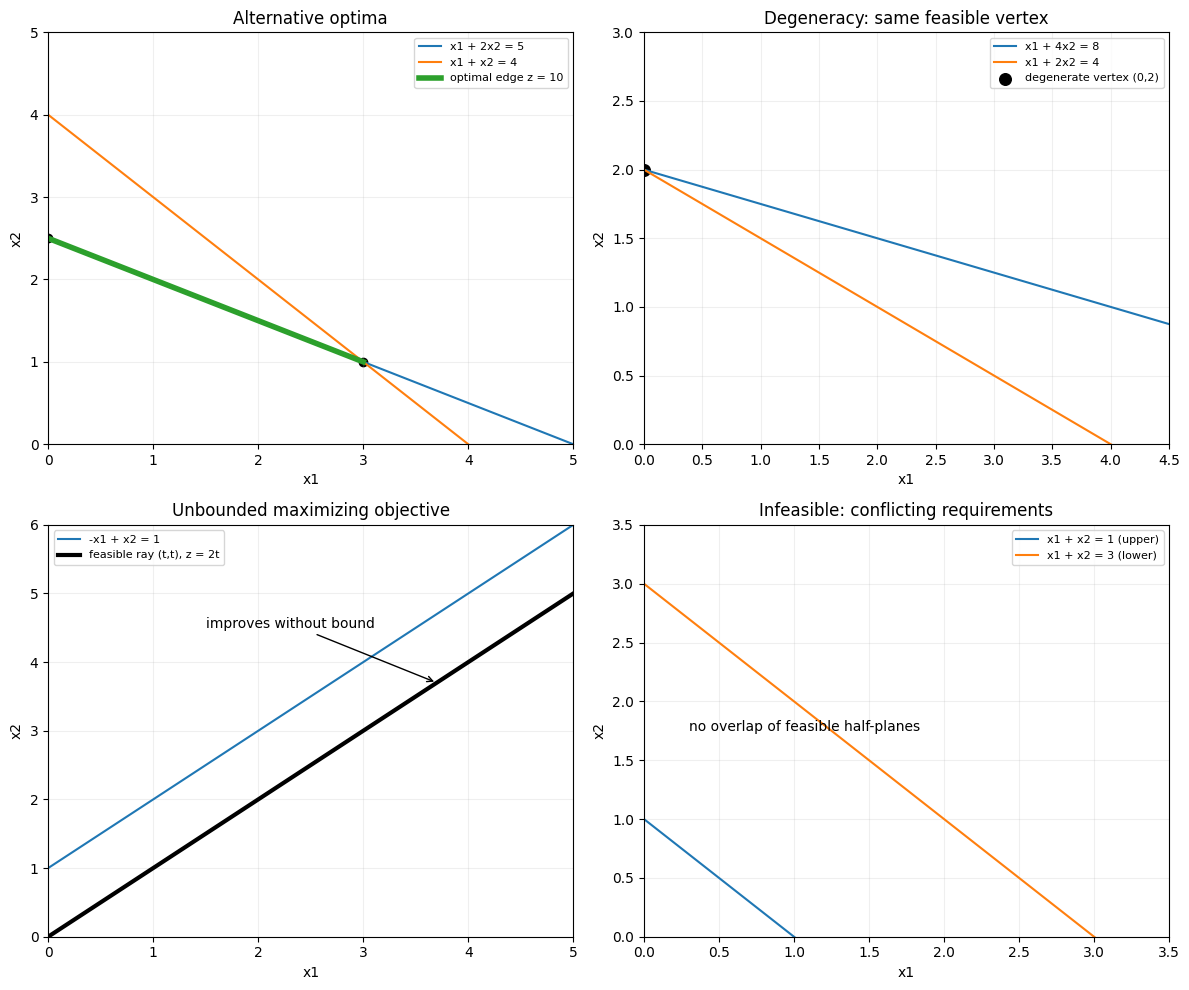

In [16]:
fig,axs=plt.subplots(2,2,figsize=(12,10))
t=np.linspace(0,5,450)
# Alternate optima
ax=axs[0,0]; ax.plot(t,(5-t)/2,label='x1 + 2x2 = 5');ax.plot(t,4-t,label='x1 + x2 = 4');ax.plot([0,3],[2.5,1],lw=4,label='optimal edge z = 10'); ax.scatter([0,3],[2.5,1],color='black');ax.set(title='Alternative optima',xlim=(0,5),ylim=(0,5))
# Degeneracy
ax=axs[0,1];ax.plot(t,(8-t)/4,label='x1 + 4x2 = 8');ax.plot(t,(4-t)/2,label='x1 + 2x2 = 4');ax.scatter([0],[2],color='black',s=70,label='degenerate vertex (0,2)');ax.set(title='Degeneracy: same feasible vertex',xlim=(0,4.5),ylim=(0,3))
# Unbounded
ax=axs[1,0];ax.plot(t,t+1,label='-x1 + x2 = 1');ax.plot(t,t,color='black',lw=3,label='feasible ray (t,t), z = 2t');ax.annotate('improves without bound',xy=(3.7,3.7),xytext=(1.5,4.5),arrowprops={'arrowstyle':'->'});ax.set(title='Unbounded maximizing objective',xlim=(0,5),ylim=(0,6))
# Infeasible
ax=axs[1,1];ax.plot(t,1-t,label='x1 + x2 = 1 (upper)');ax.plot(t,3-t,label='x1 + x2 = 3 (lower)');ax.text(.3,1.75,'no overlap of feasible half-planes');ax.set(title='Infeasible: conflicting requirements',xlim=(0,3.5),ylim=(0,3.5))
for ax in axs.flat:ax.set(xlabel='x1',ylabel='x2');ax.grid(alpha=.2);ax.legend(fontsize=8)
plt.tight_layout();plt.show()

### What each special-case outcome means in practice

- **Degenerate basic solution:** a basic variable is zero; a pivot can leave the numerical decision point and objective unchanged. This does **not by itself prove that a constraint is globally redundant**, and a careless pivot rule can cycle. Ties can be resolved by an anti-cycling rule such as Bland's rule.
- **Alternative optima:** more than one feasible production mix delivers the same best objective. A zero reduced cost of an eligible nonbasic variable can reveal another optimal extreme point; the segment between two optimal points is also optimal.
- **Unbounded objective:** a profitable entering column has no positive coefficients in the ratio test, so no leaving variable limits improvement. The model may be missing capacity constraints. An unbounded feasible *region* alone does not imply an unbounded objective.
- **Infeasible model:** constraints cannot all hold simultaneously. In Phase I, $w^*>0$ indicates that no feasible original solution exists. The manager should investigate conflicting demand minimums, capacities, and data.

The classification plots and tableau examples in this notebook use separate small models so each phenomenon can be isolated and checked.

## 6. Graphical sensitivity analysis — JOBCO

**Problem description.** A workshop makes Product 1 ($x_1$) and Product 2 ($x_2$). Product 1 earns $30/unit$ and requires 2 hours on machine 1 and 1 hour on machine 2. Product 2 earns $20/unit$ and requires 1 and 3 hours, respectively. Each machine has 8 hours/day.


$$
\max z=30x_1+20x_2
$$


$$
2x_1+x_2\le8,\qquad x_1+3x_2\le8,\qquad x\ge0.
$$


Both resource boundaries intersect at $x_1=3.2$, $x_2=1.6$, yielding $z=128$ dollars/day.

**Graphical RHS sensitivity:** move the machine-1 boundary in parallel by changing its capacity $b_1$, keeping machine 2 at 8. The original intersection remains a feasible optimum while $8/3\le b_1\le16$. Its **shadow price** is $\partial z^*/\partial b_1=14$ dollars per machine-hour within this one-at-a-time basis-validity interval.

**Graphical objective sensitivity:** the objective line's slope is $-c_1/c_2$. For the current corner to remain optimal, $1/3\le c_1/c_2\le2$. These are conditions on the slope; at the endpoints, alternate optima may appear.

### Individual equations and resource interpretation

**Production setting.** Machine 1 has eight available hours per day; Machine 2 also has eight. Product 1 consumes $(2,1)$ hours on the two machines and earns $30 per unit; Product 2 consumes $(1,3)$ hours and earns $20 per unit. Management wants the best daily production mix. The full individual LP is


$$
\begin{aligned}\max z&=30x_1+20x_2\\2x_1+x_2&\le8 &&\text{Machine 1 hours}\\x_1+3x_2&\le8 &&\text{Machine 2 hours}\\x_1,x_2&\ge0.\end{aligned}
$$


**Graphical RHS calculation.** Replace $8$ on Machine 1 with $b_1$ and solve the two binding boundary equations:


$$
2x_1+x_2=b_1,\quad x_1+3x_2=8
$$


$$
x_1=\frac{3b_1-8}{5},\qquad x_2=\frac{16-b_1}{5}.
$$


Nonnegativity requires $8/3\le b_1\le16$. Substituting into $z$ yields $z=14b_1+16$; at $b_1=8$, this is $128$, and at $b_1=9$ it is $142$. So the shadow price is $14 per added Machine-1 hour **within that interval**. The analogous Machine-2 shadow price is $2/hour$. Costs of added capacity must be subtracted before making an expansion decision.

**Objective-coefficient sensitivity.** The corner $(3.2,1.6)$ stays optimal while the profit-line slope lies between the two binding constraints: $1/3\le c_1/c_2\le2$ (for positive coefficients). With $c_2=20$ fixed, this means $20/3\le c_1\le40$; the same corner may no longer be uniquely optimal at the endpoints.


JOBCO: x= [3.2 1.6] revenue= 127.99999999999997 dual prices= [14.  2.]


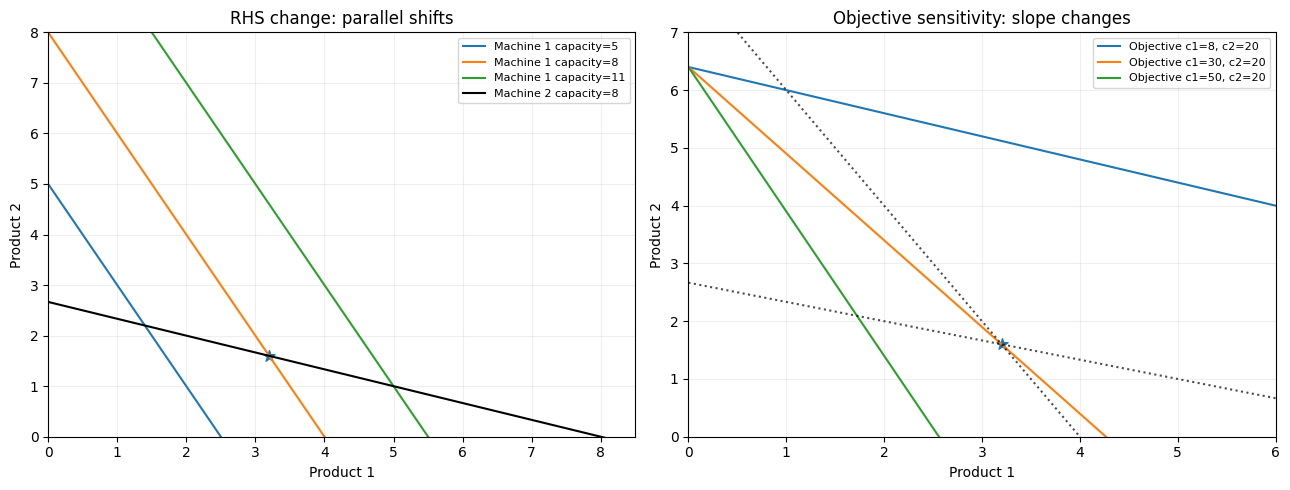

In [17]:
A_job=np.array([[2,1],[1,3]],float);b_job=np.array([8,8],float);c_job=np.array([30,20],float)
res_job=linprog(-c_job,A_ub=A_job,b_ub=b_job,bounds=[(0,None)]*2,method='highs-ds')
print('JOBCO: x=',res_job.x,'revenue=',-res_job.fun,'dual prices=',-res_job.ineqlin.marginals)
fig,axes=plt.subplots(1,2,figsize=(13,5));xx=np.linspace(0,9,300)
for b1 in (5,8,11):
    axes[0].plot(xx,b1-2*xx,label=f'Machine 1 capacity={b1}')
axes[0].plot(xx,(8-xx)/3,label='Machine 2 capacity=8',color='black')
axes[0].scatter([3.2],[1.6],s=70,marker='*');axes[0].set(xlim=(0,8.5),ylim=(0,8),xlabel='Product 1',ylabel='Product 2',title='RHS change: parallel shifts');axes[0].legend(fontsize=8)
for c1 in (8,30,50):
    axes[1].plot(xx,(128-c1*xx)/20,label=f'Objective c1={c1}, c2=20')
axes[1].plot(xx,8-2*xx,'k:',alpha=.7);axes[1].plot(xx,(8-xx)/3,'k:',alpha=.7)
axes[1].scatter([3.2],[1.6],s=70,marker='*');axes[1].set(xlim=(0,6),ylim=(0,7),xlabel='Product 1',ylabel='Product 2',title='Objective sensitivity: slope changes');axes[1].legend(fontsize=8)
for ax in axes:ax.grid(alpha=.2)
plt.tight_layout();plt.show()

**Read the plots:** shifting an RHS changes the location of a resource boundary; rotating the objective line changes which feasible vertex is preferred. The plots are conceptual illustrations: the objective lines on the right use a common intercept parameter $z=128$, so only the baseline line necessarily passes through the original optimum.

In [18]:
rows=[]
for b1 in [2.0,8/3,5,8,9,13,16,20]:
    r=linprog(-c_job,A_ub=A_job,b_ub=[b1,8],bounds=[(0,None)]*2,method='highs-ds')
    rows.append({'machine-1 capacity':round(b1,4),'x1':round(r.x[0],4),'x2':round(r.x[1],4),'revenue':round(-r.fun,4),'machine-1 marginal':round(-r.ineqlin.marginals[0],4)})
display(pd.DataFrame(rows))
print('At b1=9: expected revenue = 128 + 14*(9-8) =',128+14*(9-8))

,machine-1 capacity,x1,x2,revenue,machine-1 marginal
0,2.0000,0.0,2.0000,40.0000,20.0
1,2.6667,-0.0,2.6667,53.3333,14.0
2,5.0000,1.4,2.2000,86.0000,14.0
3,8.0000,3.2,1.6000,128.0000,14.0
4,9.0000,3.8,1.4000,142.0000,14.0
5,13.0000,6.2,0.6000,198.0000,14.0
6,16.0000,8.0,0.0000,240.0000,0.0
7,20.0000,8.0,0.0000,240.0000,0.0


At b1=9: expected revenue = 128 + 14*(9-8) = 142


**Interpretation:** An extra hour of machine 1 adds $14/day to the optimal revenue locally. At $b_1=9$ the optimum is $142/day$. This derivative is **not valid indefinitely**: beyond the basis-validity interval, resource bottlenecks and marginal values can change. Also distinguish a binding constraint (zero slack) from the marginal value of capacity; a binding constraint can have zero shadow price in a degenerate optimum.

## 7. Algebraic sensitivity analysis from the optimal basis

For a standard-form maximization LP, $\max c^Tx$ subject to $Ax=b$, $x\ge0$, partition columns into basic matrix $B$ and nonbasic matrix $N$.


$$
x_B=B^{-1}b,\qquad y^T=c_B^TB^{-1},\qquad \bar c_N=c_N-y^TN.
$$


For **maximization**, an optimal basis has $\bar c_N\le0$ (equivalently $z$-row entries $-\bar c_N\ge0$). When **only the RHS** changes by $\Delta b$:


$$
x_B^{new}=B^{-1}(b+\Delta b).
$$


The same basis stays feasible and optimal if every component is nonnegative (reduced costs are unchanged). The objective shifts by


$$
z^{new}=z^*+y^T\Delta b.
$$


When **only objective coefficients** change, $x_B$ stays fixed but reduced costs change:


$$
y_{new}^T=c_{B,new}^TB^{-1},\quad \bar c_{N,new}=c_{N,new}-y_{new}^TN\le0.
$$


These conditions describe **basis retention**, not necessarily uniqueness of the solution; at boundaries an alternative basis can be optimal.

In [19]:
# Derive JOBCO basis sensitivity directly: both decision variables are basic.
B=A_job
Binv=np.linalg.inv(B)
xB=Binv@b_job
y=c_job@Binv
print('B =',B); print('B inverse =',Binv)
print('x_B = B^-1 b =',xB,'; y = c_B^T B^-1 =',y)
# Solve one-at-a-time RHS range B^-1(b + delta e_i) >= 0.
def basis_rhs_delta_range(Binv,xB,i):
    slope=Binv[:,i];lo=-np.inf;hi=np.inf
    for value,rate in zip(xB,slope):
        if rate>1e-12:lo=max(lo,-value/rate)
        elif rate < -1e-12:hi=min(hi,-value/rate)
    return lo,hi
for i in range(2):
    lo,hi=basis_rhs_delta_range(Binv,xB,i)
    print(f'Machine {i+1}: capacity interval = [{b_job[i]+lo:.6g}, {b_job[i]+hi:.6g}]; shadow price = {y[i]:.6g}')
# For both variables basic: y = (c1,c2) @ B^-1, require y >=0 for <= constraints.
print('For variable objective coefficients (c1,c2), dual feasibility:')
print(' y1 = (3*c1-c2)/5 >=0, y2 = (-c1+2*c2)/5 >=0')
print(' Hence  c1/2 <= c2 <= 3*c1, equivalently 1/3 <= c1/c2 <= 2 (positive profits).')

B = [[2. 1.]
 [1. 3.]]
B inverse = [[ 0.6 -0.2]
 [-0.2  0.4]]
x_B = B^-1 b = [3.2 1.6] ; y = c_B^T B^-1 = [14.  2.]
Machine 1: capacity interval = [2.66667, 16]; shadow price = 14
Machine 2: capacity interval = [4, 24]; shadow price = 2
For variable objective coefficients (c1,c2), dual feasibility:
 y1 = (3*c1-c2)/5 >=0, y2 = (-c1+2*c2)/5 >=0
 Hence  c1/2 <= c2 <= 3*c1, equivalently 1/3 <= c1/c2 <= 2 (positive profits).


**A step of algebraic RHS sensitivity:** Machine 1 increases from 8 to 9 hours, so $\Delta b=(1,0)^T$. With


$$
B^{-1}=\frac15\begin{bmatrix}3&-1\\-1&2\end{bmatrix},
$$


$$
x_B^{new}=\begin{bmatrix}3.2\\1.6\end{bmatrix}+\frac15\begin{bmatrix}3\\-1\end{bmatrix}=\begin{bmatrix}3.8\\1.4\end{bmatrix}.
$$


The updated revenue is $30(3.8)+20(1.4)=142$, agreeing with the graphical and solver results. This algebra extends to any number of variables and constraints.

In [20]:
# Verify shadow prices against finite changes, and compare solver's sign convention.
rows=[]
for delta in [-1,0,.25,1,5,8,12]:
    rhs=b_job+np.array([delta,0])
    r=linprog(-c_job,A_ub=A_job,b_ub=rhs,bounds=[(0,None)]*2,method='highs-ds')
    predicted=xB+Binv@np.array([delta,0]);valid=(predicted>=-1e-9).all()
    rows.append({'delta b1':delta,'basis feasible?':valid,'basis-predicted x1':round(predicted[0],3),'basis-predicted x2':round(predicted[1],3),'basis predicted z':round(128+14*delta,3),'reoptimized z':round(-r.fun,3)})
display(pd.DataFrame(rows))
print('Important: scipy minimizes -revenue, so its reported minimization marginals are NEGATIVE of the revenue shadow prices.')

,delta b1,basis feasible?,basis-predicted x1,basis-predicted x2,basis predicted z,reoptimized z
0,-1.00,True,2.60,1.80,114.0,114.0
1,0.00,True,3.20,1.60,128.0,128.0
2,0.25,True,3.35,1.55,131.5,131.5
3,1.00,True,3.80,1.40,142.0,142.0
4,5.00,True,6.20,0.60,198.0,198.0
5,8.00,True,8.00,0.00,240.0,240.0
6,12.00,False,10.40,-0.80,296.0,240.0


Important: scipy minimizes -revenue, so its reported minimization marginals are NEGATIVE of the revenue shadow prices.


### 7.1 Reduced costs, objective coefficient ranges, and simultaneous changes

For a general LP, the reduced cost $\bar c_j=c_j-y^TA_j$ measures the marginal effect of introducing a nonbasic decision variable while respecting the **current basis representation**. For maximization, a strictly negative reduced cost means the variable cannot improve the current optimal objective locally through that basis; zero may indicate an alternative optimum.

Objective coefficient sensitivity can be checked by updating $c_B$ or $c_N$, recomputing the dual multipliers and all nonbasic reduced costs, and testing their signs. **One-at-a-time allowable ranges must not be combined naively**: simultaneous changes should be tested using the full matrix equations. Likewise, for simultaneous RHS changes, use $B^{-1}(b+\Delta b)\ge0$ rather than assuming that individually valid changes can always be combined.

In [21]:
# JOBCO analytical objective-coefficient experiment: both x1 and x2 basic, slack reduced costs = -y.
tests=[(30,20),(35,25),(10,20),(45,20),(30,100)]
out=[]
for c1,c2 in tests:
    new_c=np.array([c1,c2],float); yy=new_c@Binv
    r=linprog(-new_c,A_ub=A_job,b_ub=b_job,bounds=[(0,None)]*2,method='highs-ds')
    retained=np.all(yy>=-1e-10)
    out.append({'c1':c1,'c2':c2,'basis dual feasible?':retained,'candidate x':str(np.round(xB,3)),'reoptimized x':str(np.round(r.x,3)),'optimum revenue':round(-r.fun,2)})
display(pd.DataFrame(out))

,c1,c2,basis dual feasible?,candidate x,reoptimized x,optimum revenue
0,30,20,True,[3.2 1.6],[3.2 1.6],128.00
1,35,25,True,[3.2 1.6],[3.2 1.6],152.00
2,10,20,True,[3.2 1.6],[3.2 1.6],64.00
3,45,20,False,[3.2 1.6],[4. 0.],180.00
4,30,100,False,[3.2 1.6],[0. 2.667],266.67


## Algebraic objective/RHS sensitivity — TOYCO three-product benchmark

**Problem.** A toy plant assembles trains ($x_1$), trucks ($x_2$), and cars ($x_3$). Daily operation time limits are **430, 460, and 420 minutes**, and revenue contributions are **$3, $2, and $5 per unit**. Each train uses $(1,3,1)$ minutes, truck $(2,0,4)$, and car $(1,2,0)$ across operations 1–3. Management maximizes daily revenue under these available processing times.


$$
\max z=3x_1+2x_2+5x_3
$$


$$
\begin{aligned}x_1+2x_2+x_3&\le430&&\text{Operation 1}\\3x_1+2x_3&\le460&&\text{Operation 2}\\x_1+4x_2&\le420&&\text{Operation 3}\\x_1,x_2,x_3&\ge0.\end{aligned}
$$


Introduce slacks $s_1,s_2,s_3$. With the optimal basis ordered $(x_2,x_3,s_3)$, compute the **basis matrix** $B$, $B^{-1}$, $x_B=B^{-1}b$, the shadow-price row $y^T=c_B^TB^{-1}$, and the nonbasic reduced costs $\bar c_N=c_N-y^TN$. This uses the actual numerical coefficients rather than leaving sensitivity analysis in generic summation notation.

In [22]:
A_toy=np.array([[1,2,1],[3,0,2],[1,4,0]],float)
b_toy=np.array([430,460,420],float)
c_toy=np.array([3,2,5],float)
r_toy=linprog(-c_toy,A_ub=A_toy,b_ub=b_toy,bounds=[(0,None)]*3,method='highs-ds')
assert r_toy.success
A_toy_aug=np.hstack([A_toy,np.eye(3)])
c_toy_aug=np.r_[c_toy,np.zeros(3)]
basis_toy=[1,2,5]
Btoy=A_toy_aug[:,basis_toy]
Btoy_inv=np.linalg.inv(Btoy)
xBtoy=Btoy_inv@b_toy
ytoy=c_toy_aug[basis_toy]@Btoy_inv
rc_toy=c_toy_aug-ytoy@A_toy_aug
print('Optimal (trains, trucks, cars) =',r_toy.x,' revenue ($/day) =',-r_toy.fun)
print('B =\n',Btoy,'\nB inverse =\n',Btoy_inv)
print('Basic solution [trucks,cars,slack3] =',xBtoy)
print('Shadow prices [$ per extra minute] =',ytoy)
print('Reduced costs [train,truck,car,slack1,slack2,slack3] =',rc_toy)
assert np.allclose(r_toy.x,[0,100,230])
assert np.allclose(ytoy,[1,2,0])
assert np.allclose(rc_toy,[-4,0,0,-1,-2,0])


Optimal (trains, trucks, cars) = [  0. 100. 230.]  revenue ($/day) = 1350.0
B =
 [[2. 1. 0.]
 [0. 2. 0.]
 [4. 0. 1.]] 
B inverse =
 [[ 0.5  -0.25  0.  ]
 [ 0.    0.5   0.  ]
 [-2.    1.    1.  ]]
Basic solution [trucks,cars,slack3] = [100. 230.  20.]
Shadow prices [$ per extra minute] = [1. 2. 0.]
Reduced costs [train,truck,car,slack1,slack2,slack3] = [-4.  0.  0. -1. -2.  0.]


**Interpret the computed values.** Make **100 trucks and 230 cars**, and no trains, for **$1,350/day revenue**. Operations 1 and 2 are fully used; operation 3 has **20 unused minutes**. Shadow prices are respectively **$1/min, $2/min, and $0/min**. Within their valid sensitivity regions, one more operation-2 minute is worth $2 of additional revenue before overtime costs. Train's reduced cost is **−$4/unit**: holding the current basis locally, introducing a train requires enough high-value capacity that it reduces the objective by $4/unit despite its $3 revenue.

For simultaneous RHS changes $\Delta b=(D_1,D_2,D_3)^T$, the same basis remains feasible if


$$
x_B^{new}=B^{-1}\begin{bmatrix}430+D_1\\460+D_2\\420+D_3\end{bmatrix}\ge0.
$$


The objective then changes by $\Delta z=D_1+2D_2$. With **one RHS changed at a time**, we can calculate the exact basis-feasibility limits, not just examine small perturbations.

In [23]:
# One-at-a-time basis feasibility intervals, including the slack in operation 3
for i,name in enumerate(['Operation 1','Operation 2','Operation 3']):
    lo,hi=basis_rhs_delta_range(Btoy_inv,xBtoy,i)
    print(f'{name}: allowable delta=[{lo:.3f},{hi:.3f}], RHS=[{b_toy[i]+lo:.3f},{b_toy[i]+hi:.3f}], shadow price={ytoy[i]:.2f}')
for D in [np.array([-30,-12,10]),np.array([50,-20,-10]),np.array([30,-12,100])]:
    xnew=Btoy_inv@(b_toy+D)
    pred=1350+ytoy@D
    r=linprog(-c_toy,A_ub=A_toy,b_ub=b_toy+D,bounds=[(0,None)]*3,method='highs-ds')
    print('Delta',D,'basic values',np.round(xnew,2),'basis-feasible?',np.all(xnew>=-1e-9),'linear prediction',pred,'re-solved objective',-r.fun if r.success else r.message)


Operation 1: allowable delta=[-200.000,10.000], RHS=[230.000,440.000], shadow price=1.00
Operation 2: allowable delta=[-20.000,400.000], RHS=[440.000,860.000], shadow price=2.00
Operation 3: allowable delta=[-20.000,inf], RHS=[400.000,inf], shadow price=0.00
Delta [-30 -12  10] basic values [ 88. 224.  78.] basis-feasible? True linear prediction 1296.0 re-solved objective 1296.0
Delta [ 50 -20 -10] basic values [ 130.  220. -110.] basis-feasible? False linear prediction 1360.0 re-solved objective 1305.0
Delta [ 30 -12 100] basic values [118. 224.  48.] basis-feasible? True linear prediction 1356.0 re-solved objective 1356.0


**Objective-coefficient sensitivity.** Let $d_1,d_2,d_3$ be changes in the train, truck, and car revenue coefficients. Recompute the row $y(d)^T=c_B(d)^{\mathsf T}B^{-1}$, where $c_B(d)=(2+d_2,\;5+d_3,\;0)^T$ and test **every nonbasic** reduced cost: $\bar c_j(d)\le0$ for maximization. This protects optimality of the current basis while its primal production plan remains feasible. One-at-a-time profit intervals are not automatically safe for **simultaneous** changes. The code below checks the complete condition and compares with a fresh solve.

In [24]:
def test_toy_objective_change(d):
    newc=c_toy_aug.copy();newc[:3]+=d
    newy=newc[basis_toy]@Btoy_inv
    newrc=newc-newy@A_toy_aug
    nonbasic=[j for j in range(6) if j not in basis_toy]
    stays=bool(np.all(newrc[nonbasic]<=1e-9))
    r=linprog(-newc[:3],A_ub=A_toy,b_ub=b_toy,bounds=[(0,None)]*3,method='highs-ds')
    return {'delta':d,'reduced costs (nonbasic)':np.round(newrc[nonbasic],4),
            'same basis optimal?':stays,'basis objective':newc[basis_toy]@xBtoy,
            're-solved objective':-r.fun,'re-solved production':np.round(r.x,3)}
for d in [np.array([-1,-1,1]),np.array([3,6,-2]),np.array([4,0,0])]:
    print(test_toy_objective_change(d))


{'delta': array([-1, -1,  1]), 'reduced costs (nonbasic)': array([-6.75, -0.5 , -2.75]), 'same basis optimal?': True, 'basis objective': np.float64(1480.0), 're-solved objective': 1480.0, 're-solved production': array([  0., 100., 230.])}
{'delta': array([ 3,  6, -2]), 'reduced costs (nonbasic)': array([ 3.5, -4. ,  0.5]), 'same basis optimal?': False, 'basis objective': np.float64(1490.0), 're-solved objective': 1525.0, 're-solved production': array([ 10. , 102.5, 215. ])}
{'delta': array([4, 0, 0]), 'reduced costs (nonbasic)': array([ 0., -1., -2.]), 'same basis optimal?': True, 'basis objective': np.float64(1350.0), 're-solved objective': 1350.0, 're-solved production': array([ 10. , 102.5, 215. ])}


For the first objective-change scenario ($d=(-1,-1,+1)$), the original production mix remains optimal and the revenue becomes **$1,480/day**. The second scenario ($d=(+3,+6,-2)$) shows why individually acceptable coefficient movements should **not** be combined without testing the simultaneous reduced costs. At an interval endpoint (such as a zero nonbasic reduced cost), the current basis may stay optimal but the optimum need not be unique.


## 8. Industrial production-planning LP — four named products and every constraint

**Problem description.** A hypothetical manufacturer must decide how many units/day of **Panel A, Panel B, Kit C, and Module D** to produce. Cutting, assembly, and testing have daily minute budgets, and sales forecasts impose product-specific upper limits. Unit contribution margins (selling revenue minus modeled variable costs) are $55, $47, $65, and $38. All numbers in this dataset are **illustrative**, not measured factory data.

| Production parameter | Panel A | Panel B | Kit C | Module D | Daily capacity |
|---|---:|---:|---:|---:|---:|
| Cutting minutes/unit | 3 | 4 | 2 | 1 | 850 min |
| Assembly minutes/unit | 5 | 2 | 4 | 3 | 1,000 min |
| Testing minutes/unit | 2 | 3 | 5 | 2 | 740 min |
| Margin ($/unit) | 55 | 47 | 65 | 38 | — |
| Maximum demand (units/day) | 120 | 140 | 100 | 160 | — |

Let $x_A,x_B,x_C,x_D$ denote daily quantities of the four named products. The **exact mathematical model being solved by the next Python cell** is:


$$
\boxed{\max Z=55x_A+47x_B+65x_C+38x_D}
$$


subject to the three **separate processing-capacity constraints**:


$$
\begin{aligned}
3x_A+4x_B+2x_C+x_D&\le850 &&\text{cutting (min/day)}\\
5x_A+2x_B+4x_C+3x_D&\le1000 &&\text{assembly (min/day)}\\
2x_A+3x_B+5x_C+2x_D&\le740 &&\text{testing (min/day)}.
\end{aligned}
$$


and four **separate demand limits**:


$$
x_A\le120,\quad x_B\le140,\quad x_C\le100,\quad x_D\le160,\qquad x_A,x_B,x_C,x_D\ge0.
$$


The manufacturing interpretation is straightforward: each product consumes finite time on every operation, and any production recommendation must satisfy both line capacities and forecast demand. The optimization assumes divisible quantities, deterministic parameters, and no sequencing or changeover effects. Those are limitations if implementing the result on a real shop floor.

**Implementation:** `scipy.optimize.linprog` with the HiGHS dual-simplex solver solves the continuous LP. The next cells print its full solution, constraint usage and slacks, and resource shadow prices. The solver handles the calculation; the notebook checks feasibility and explains the capacity trade-offs.


In [25]:
products=['Panel A','Panel B','Kit C','Module D']
resources=['Cutting (min)','Assembly (min)','Testing (min)']
profit=np.array([55,47,65,38],float)
use=np.array([[3,4,2,1],[5,2,4,3],[2,3,5,2]],float)
capacity=np.array([850,1000,740],float)
demand=np.array([120,140,100,160],float)
display(pd.DataFrame(use,index=resources,columns=products))
display(pd.DataFrame({'product':products,'margin ($/unit)':profit,'demand limit (units)':demand}))
r_prod=linprog(-profit,A_ub=use,b_ub=capacity,bounds=[(0,float(v)) for v in demand],method='highs-ds')
assert r_prod.success
x=r_prod.x
print('Solver:',r_prod.message); print('Optimal contribution margin ($/day):',-r_prod.fun)
display(pd.DataFrame({'product':products,'optimal units/day':x,'demand upper bound':demand}))
display(pd.DataFrame({'operation':resources,'used capacity':use@x,'available capacity':capacity,'unused':capacity-use@x,'utilization (%)':100*(use@x)/capacity,'shadow price ($/min)':-r_prod.ineqlin.marginals}))

,Panel A,Panel B,Kit C,Module D
Cutting (min),3.0,4.0,2.0,1.0
Assembly (min),5.0,2.0,4.0,3.0
Testing (min),2.0,3.0,5.0,2.0


,product,margin ($/unit),demand limit (units)
0,Panel A,55.0,120.0
1,Panel B,47.0,140.0
2,Kit C,65.0,100.0
3,Module D,38.0,160.0


Solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Optimal contribution margin ($/day): 14452.5


,product,optimal units/day,demand upper bound
0,Panel A,92.5,120.0
1,Panel B,118.0,140.0
2,Kit C,0.0,100.0
3,Module D,100.5,160.0


,operation,used capacity,available capacity,unused,utilization (%),shadow price ($/min)
0,Cutting (min),850.0,850.0,-1.13687e-13,100.0,2.25
1,Assembly (min),1000.0,1000.0,0.00000e+00,100.0,6.25
2,Testing (min),740.0,740.0,-1.13687e-13,100.0,8.50


In [26]:
# Independent numerical audit: objective and every individual constraint
audit=pd.DataFrame({'constraint':['Cutting','Assembly','Testing','Demand Panel A','Demand Panel B','Demand Kit C','Demand Module D'],
                     'LHS':np.r_[use@x,x],'limit':np.r_[capacity,demand]})
audit['slack']=audit['limit']-audit['LHS']
audit['satisfied']=audit['slack']>=-1e-7
assert audit['satisfied'].all() and np.isclose(profit@x,-r_prod.fun)
print('Recomputed objective ($/day):',profit@x)
display(audit)
print('Demand-upper-bound shadow values ($/extra unit):',-r_prod.upper.marginals)
print('Interpretation: equality means binding; positive slack means unused capacity/room under the demand cap.')

Recomputed objective ($/day): 14452.5


,constraint,LHS,limit,slack,satisfied
0,Cutting,850.0,850.0,-1.13687e-13,True
1,Assembly,1000.0,1000.0,0.00000e+00,True
2,Testing,740.0,740.0,-1.13687e-13,True
3,Demand Panel A,92.5,120.0,2.75000e+01,True
4,Demand Panel B,118.0,140.0,2.20000e+01,True
5,Demand Kit C,0.0,100.0,1.00000e+02,True
6,Demand Module D,100.5,160.0,5.95000e+01,True


Demand-upper-bound shadow values ($/extra unit): [-0. -0. -0. -0.]
Interpretation: equality means binding; positive slack means unused capacity/room under the demand cap.


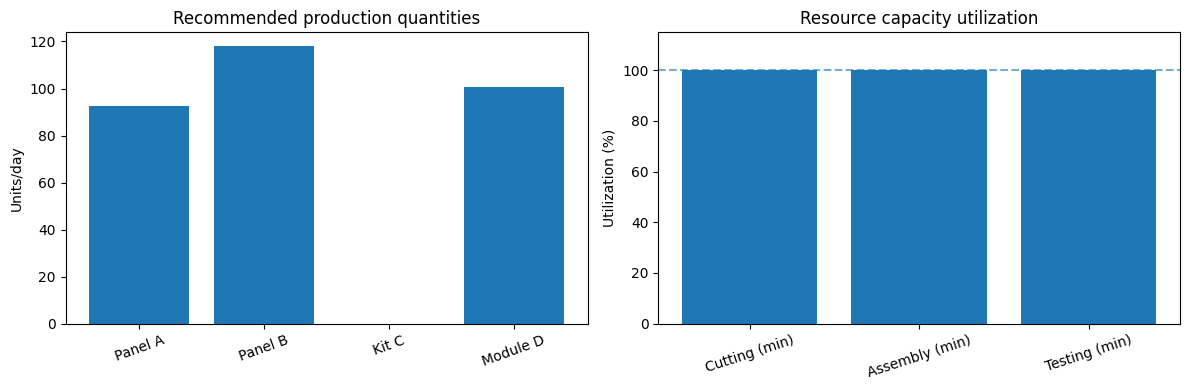

Verified: every capacity and demand constraint satisfied.


In [27]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].bar(products,x);axs[0].set(ylabel='Units/day',title='Recommended production quantities');axs[0].tick_params(axis='x',rotation=20)
axs[1].bar(resources,100*(use@x)/capacity);axs[1].axhline(100,linestyle='--',alpha=.6);axs[1].set(ylabel='Utilization (%)',title='Resource capacity utilization',ylim=(0,115));axs[1].tick_params(axis='x',rotation=18)
plt.tight_layout();plt.show()
assert np.all(use@x<=capacity+1e-7) and np.all(x<=demand+1e-7)
print('Verified: every capacity and demand constraint satisfied.')

**Industrial interpretation checklist:** The output table provides the actual profit-maximizing continuous plan for the illustrative data. Read the four product quantities directly from the solver (do not infer them from chart heights). A utilization of **100%** means that operation is a binding resource at this solution. A positive maximization shadow price gives its **local** marginal daily profit per additional minute, before expansion costs. A nonbinding operation has unused minutes and usually a zero marginal value at a nondegenerate solution. Use these values to screen bottlenecks before deciding whether overtime or another machine is worth purchasing.

For this specific table, the **decision variables** are the displayed Panel A, Panel B, Kit C, and Module D output quantities. The **objective** is their sum of per-unit margins, in $/day. For each of cutting, assembly and testing, compare the printed *used* and *available* minutes; their difference is the exact unused capacity. The shadow price, if applicable, is in **$/additional minute**, not $/additional product. Demand constraints are passed as variable upper bounds, so their marginal values are reported separately under `result.upper.marginals`, rather than in the three-row resource-dual vector. Do not treat a local shadow price as valid for arbitrarily large changes.


## 9. Summary of which tool to use

| Task | Python package / approach | Output to discuss |
|---|---|---|
| Feasible polygon and objective lines (two variables) | NumPy + Matplotlib | Corner points, feasible area, optimum |
| Full Simplex tableau mechanics | Transparent educational NumPy implementation above | Entering/leaving variables, ratios, pivot rows, path |
| Big-M teaching example | Same tableau engine with a finite penalty | Artificial values, objective penalties, conditioning risk |
| Two-phase teaching example | Explicit auxiliary objective + restored objective | Phase I feasibility; Phase II optimum |
| Production LP | SciPy `linprog` with HiGHS | Decision variables, feasibility, optimal objective |
| RHS sensitivity | $B^{-1}(b+\Delta b)$ plus reoptimization | Feasibility ranges and shadow prices |
| Objective sensitivity | $c_j-c_B^TB^{-1}A_j$ | Reduced costs and basis-optimality ranges |

**What is and is not proven:** Numerical agreement among the graphical, educational-tableau, and HiGHS solutions validates these examples. It does not prove the educational Simplex implementation is safe for every degenerate, ill-conditioned, redundant, or large-scale LP. For industrial work use HiGHS, Gurobi, or another maintained optimization solver. For algorithms implemented in this notebook, see their explicitly printed iteration history rather than assuming a commercial solver exposes identical internal steps.

**Reproduce in Colab:** Run cells from top to bottom. Required packages: `numpy`, `pandas`, `matplotlib`, and `scipy`. No external files or downloads are required.

### Reference

Hamdy A. Taha, *Operations Research: An Introduction*, 8th edition, Sections 2.1–2.2 and 3.1–3.6. The final four-product manufacturing dataset is illustrative. Numerical optimization results and graphics are generated by the notebook code.